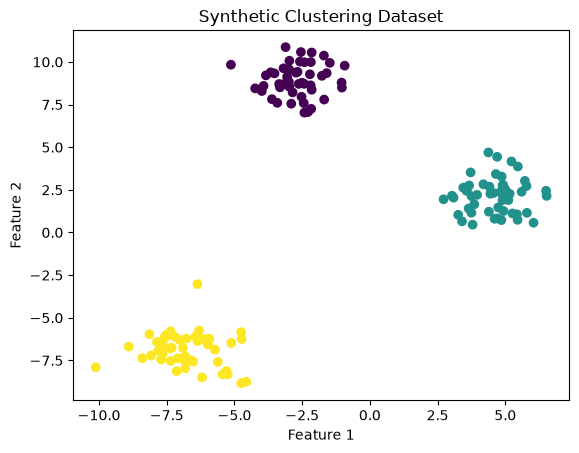

In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

# Generate 150 data points in 3 clusters
X, y = make_blobs(
    n_samples=150,
    centers=3,
    n_features=2,
    random_state=42
)

# Visualize actual groups
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Clustering Dataset")
plt.show()

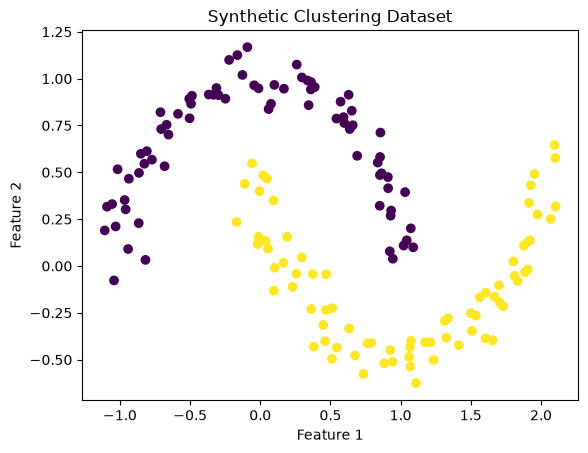

In [5]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.datasets import make_moons

# Generate 150 data points in 3 clusters
X, y = make_moons(n_samples=150, noise=0.08, random_state=42)

# Visualize actual groups
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Clustering Dataset")
plt.show()

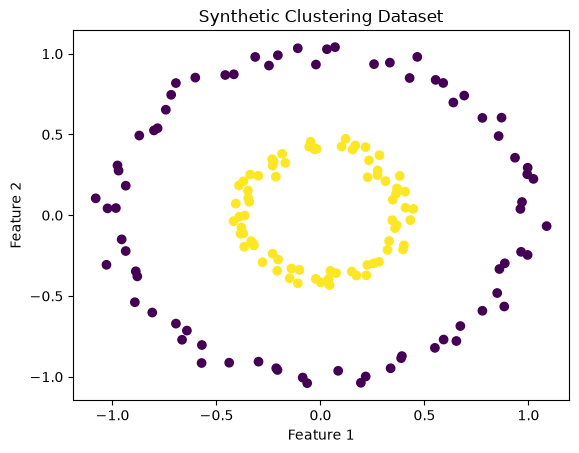

In [7]:
from sklearn.datasets import make_circles
X, y = make_circles(n_samples=150, noise=0.04, factor=0.4, random_state=42)
# Visualize actual groups
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic Clustering Dataset")
plt.show()

Number of data points: 150
Number of clusters: 2
Silhouette Score: 0.4931
Adjusted Rand Index: 0.2655


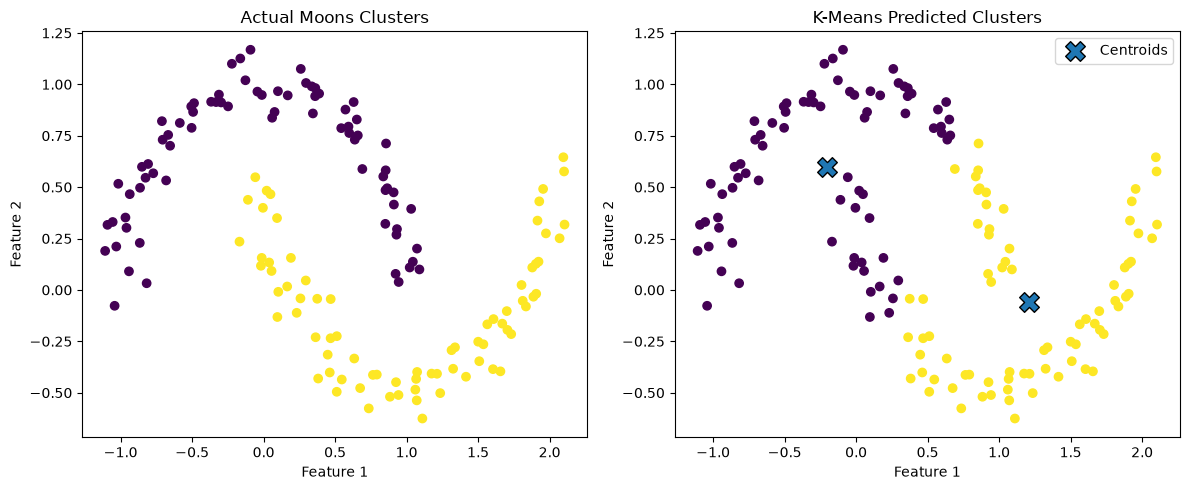

In [8]:

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Generate the Moons dataset
X, y = make_moons(
    n_samples=150,
    noise=0.08,
    random_state=42
)

# 2. Apply K-Means
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

y_pred = kmeans.fit_predict(X)

# 3. Evaluate clustering
sil_score = silhouette_score(X, y_pred)
ari_score = adjusted_rand_score(y, y_pred)

print("Number of data points:", len(X))
print("Number of clusters:", len(set(y_pred)))
print("Silhouette Score:", round(sil_score, 4))
print("Adjusted Rand Index:", round(ari_score, 4))

# 4. Visualize the results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Actual Moons Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=y_pred)
plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=200,
    edgecolor="black",
    label="Centroids"
)
plt.title("K-Means Predicted Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.tight_layout()
plt.show()


Total data points: 150
Number of clusters: 3
Number of noise points: 2
Silhouette Score: -0.0806
Adjusted Rand Index: 0.9019


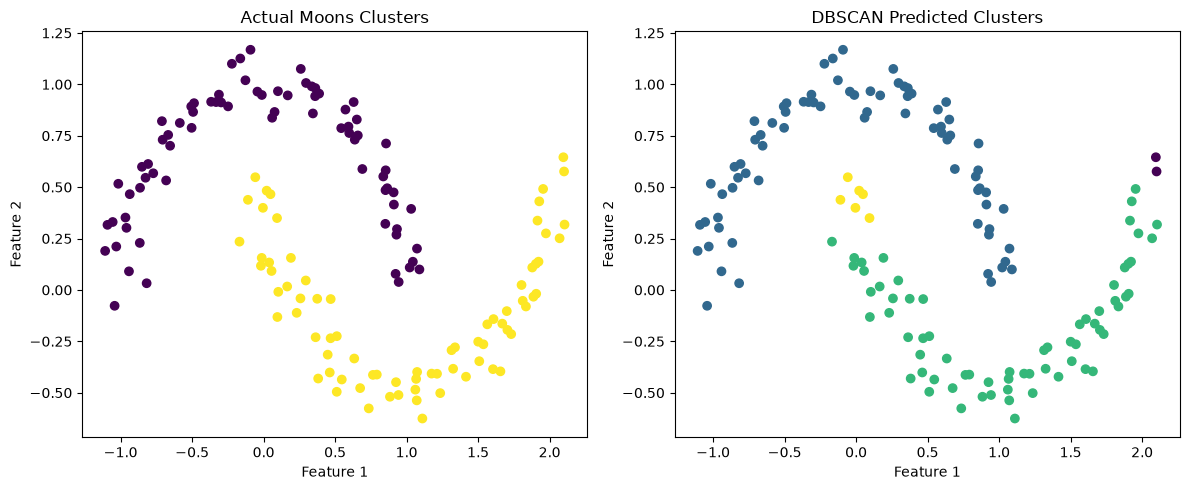

In [9]:

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Generate the Moons dataset
X, y = make_moons(
    n_samples=150,
    noise=0.08,
    random_state=42
)

# 2. Apply DBSCAN
dbscan = DBSCAN(
    eps=0.2,
    min_samples=5
)

y_pred = dbscan.fit_predict(X)

# 3. Evaluate clustering
n_clusters = len(set(y_pred) - {-1})
n_noise = list(y_pred).count(-1)

print("Total data points:", len(X))
print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

# Silhouette score (requires at least 2 clusters)
if 2 <= n_clusters < len(X):
    print("Silhouette Score:",
          round(silhouette_score(X, y_pred), 4))
else:
    print("Silhouette Score: Cannot be calculated")

print("Adjusted Rand Index:",
      round(adjusted_rand_score(y, y_pred), 4))

# 4. Visualize results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Actual Moons Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap="viridis")
plt.title("DBSCAN Predicted Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()


In [10]:
%pip install scikit-fuzzy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


Total data points: 150
Number of clusters: 2
Iterations: 11
Fuzzy Partition Coefficient: 0.78
Silhouette Score: 0.4931
Adjusted Rand Index: 0.2655


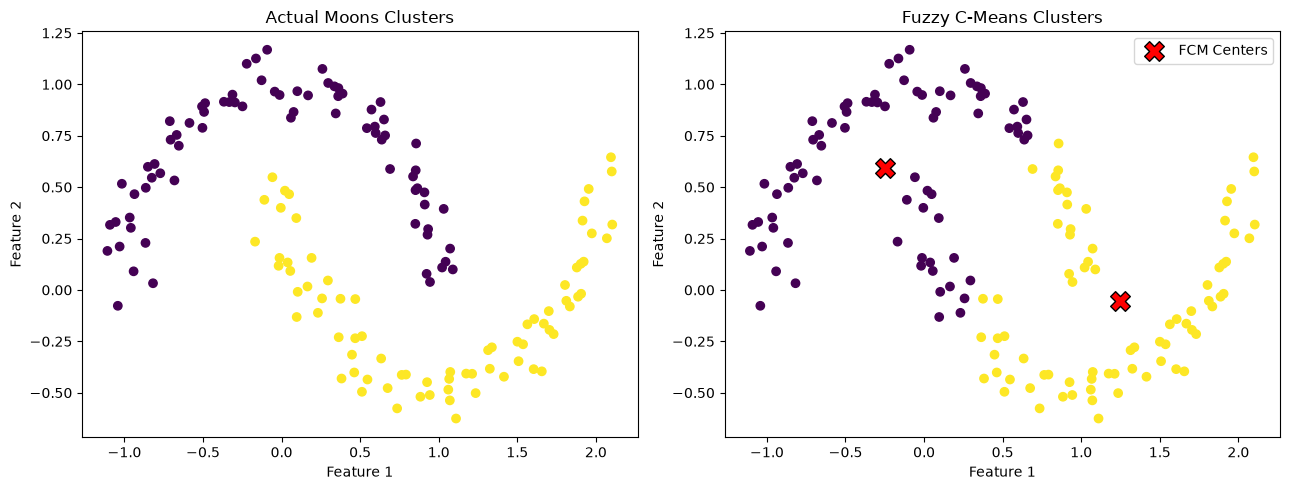


Membership values for first 5 points:
[[0.829 0.171]
 [0.54  0.46 ]
 [0.055 0.945]
 [0.943 0.057]
 [0.955 0.045]]


In [11]:

import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz

from sklearn.datasets import make_moons
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Generate Moons dataset
X, y = make_moons(
    n_samples=150,
    noise=0.08,
    random_state=42
)

# 2. Prepare data for Fuzzy C-Means
# skfuzzy expects shape: (features, samples)
data = X.T

# 3. Apply Fuzzy C-Means
centers, membership, initial_membership, distances, \
    objective, iterations, fpc = fuzz.cluster.cmeans(
        data=data,
        c=2,
        m=2,
        error=0.005,
        maxiter=1000,
        seed=42
    )

# 4. Assign each point to its highest-membership cluster
y_pred = np.argmax(membership, axis=0)

# 5. Evaluate clustering
print("Total data points:", len(X))
print("Number of clusters:", len(centers))
print("Iterations:", iterations)
print("Fuzzy Partition Coefficient:", round(fpc, 4))
print("Silhouette Score:", round(silhouette_score(X, y_pred), 4))
print("Adjusted Rand Index:", round(adjusted_rand_score(y, y_pred), 4))

# 6. Visualize actual and predicted clusters
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis")
plt.title("Actual Moons Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap="viridis")
plt.scatter(
    centers[:, 0], centers[:, 1],
    marker="X", s=200, edgecolor="black",
    color="red", label="FCM Centers"
)
plt.title("Fuzzy C-Means Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()

plt.tight_layout()
plt.show()

# 7. Show membership values for the first 5 points
print("\nMembership values for first 5 points:")
print(np.round(membership[:, :5].T, 3))


Number of clusters: 2
Silhouette Score: 0.4675
Adjusted Rand Index: 0.4588


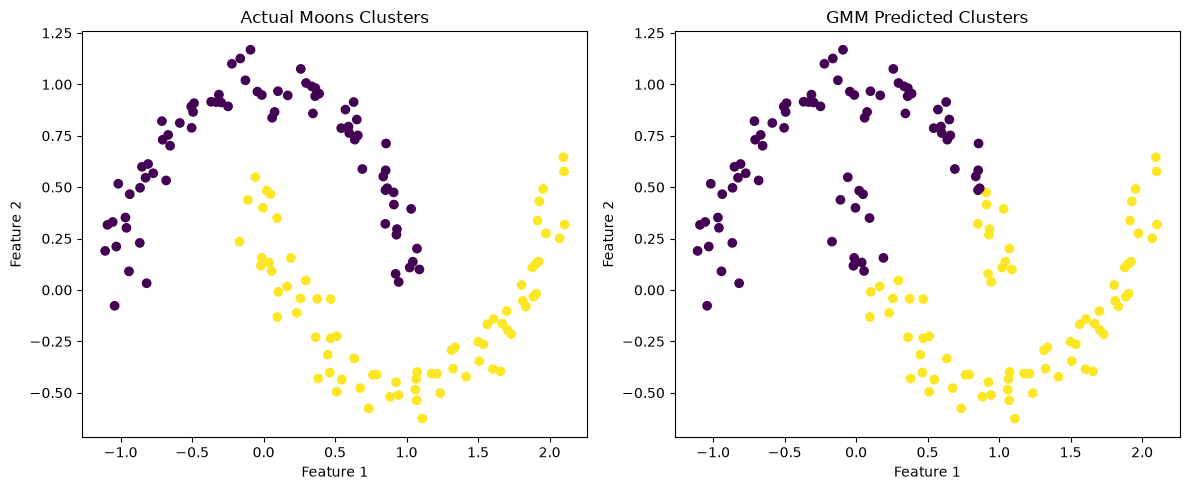


Cluster probabilities for first 5 points:
[[0.993 0.007]
 [0.981 0.019]
 [0.    1.   ]
 [0.988 0.012]
 [0.991 0.009]]


In [12]:

import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Generate data
X, y = make_moons(
    n_samples=150,
    noise=0.08,
    random_state=42
)

# 2. Apply Gaussian Mixture Model
gmm = GaussianMixture(
    n_components=2,
    covariance_type="full",
    random_state=42,
    n_init=5
)

gmm.fit(X)

# 3. Predict cluster labels and probabilities
y_pred = gmm.predict(X)
probabilities = gmm.predict_proba(X)

# 4. Evaluate
print("Number of clusters:", len(set(y_pred)))
print("Silhouette Score:", round(silhouette_score(X, y_pred), 4))
print("Adjusted Rand Index:", round(adjusted_rand_score(y, y_pred), 4))

# 5. Visualize clusters
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X[:, 0], X[:, 1], c=y)
plt.title("Actual Moons Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.subplot(1, 2, 2)
plt.scatter(X[:, 0], X[:, 1], c=y_pred)
plt.title("GMM Predicted Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")

plt.tight_layout()
plt.show()

# 6. Inspect probabilities for 5 points
print("\nCluster probabilities for first 5 points:")
print(probabilities[:5].round(3))


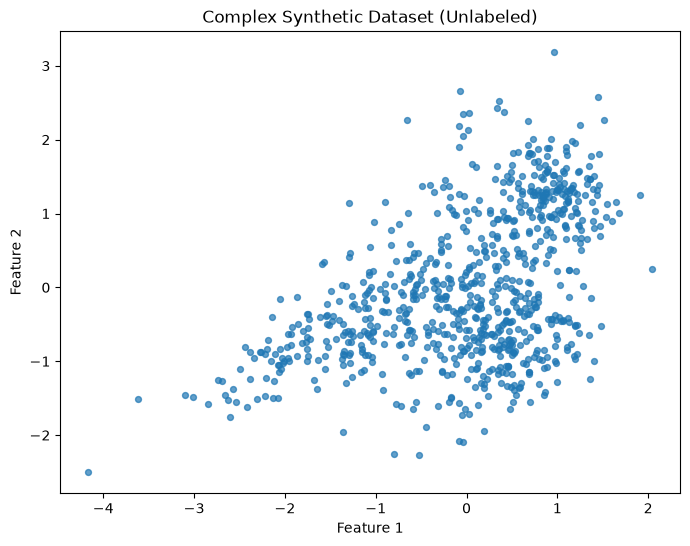

Dataset shape: (800, 2)
Number of data points: 800
Number of features: 2


In [13]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, silhouette_score

# 1. Generate overlapping clusters with different shapes and sizes
X, y_true = make_blobs(
    n_samples=[180, 250, 150, 220],
    centers=[
        [-2, 0],
        [0, 0],
        [2, 2],
        [1, -2]
    ],
    cluster_std=[1.3, 1.5, 0.7, 1.0],
    random_state=42
)

# 2. Rotate and stretch some of the data to make shapes more complex
X[y_true == 0] = X[y_true == 0] @ np.array([
    [1.5, 0.8],
    [0.0, 0.6]
])

X[y_true == 1] = X[y_true == 1] @ np.array([
    [0.7, -0.5],
    [0.8, 1.4]
])

# 3. Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Plot the generated dataset
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], s=18, alpha=0.7)
plt.title("Complex Synthetic Dataset (Unlabeled)")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

print("Dataset shape:", X_scaled.shape)
print("Number of data points:", len(X_scaled))
print("Number of features:", X_scaled.shape[1])


Adjusted Rand Index: 0.4215
Silhouette Score: 0.4156
Average Log-Likelihood: -2.439


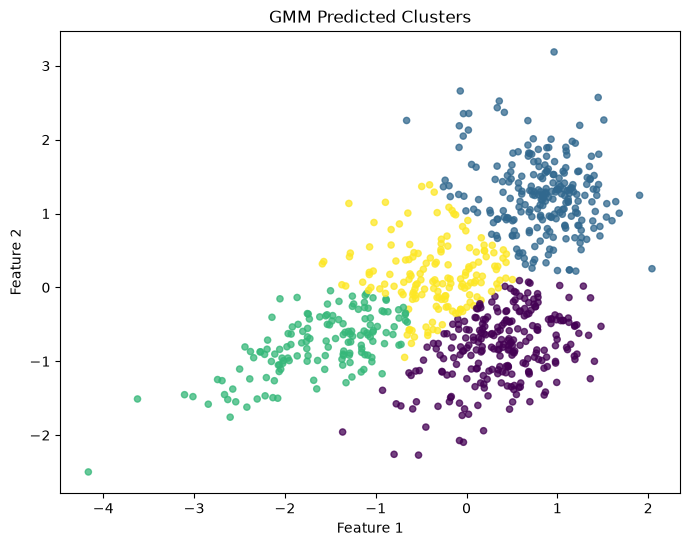

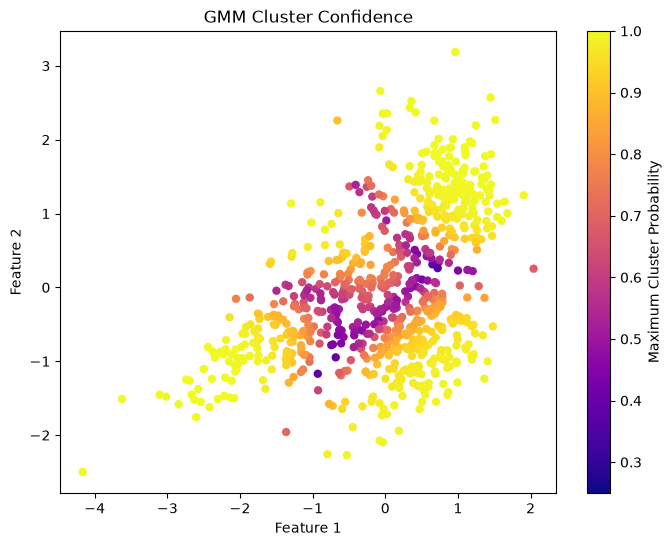


Most uncertain points:
Point index | Cluster probabilities
644 [0.324 0.363 0.021 0.293]
29 [0.296 0.    0.38  0.324]
66 [0.244 0.391 0.028 0.337]
507 [0.377 0.    0.229 0.393]
219 [0.43  0.105 0.036 0.43 ]
607 [0.159 0.    0.43  0.41 ]
657 [0.401 0.445 0.006 0.147]
213 [0.132 0.    0.42  0.448]
160 [0.261 0.    0.29  0.448]
196 [0.061 0.447 0.039 0.453]


In [14]:

# Fit Gaussian Mixture Model
gmm = GaussianMixture(
    n_components=4,
    covariance_type="full",
    n_init=5,
    random_state=42
)

gmm.fit(X_scaled)

# Predict cluster labels
y_pred = gmm.predict(X_scaled)

# Estimate probability of each cluster
probs = gmm.predict_proba(X_scaled)

# Evaluate
print("Adjusted Rand Index:",
      round(adjusted_rand_score(y_true, y_pred), 4))

print("Silhouette Score:",
      round(silhouette_score(X_scaled, y_pred), 4))

print("Average Log-Likelihood:",
      round(gmm.score(X_scaled), 4))

# Plot predicted clusters
plt.figure(figsize=(8, 6))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_pred,
    s=20,
    alpha=0.75,
    cmap="viridis"
)
plt.title("GMM Predicted Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Plot uncertainty: maximum membership probability
confidence = probs.max(axis=1)

plt.figure(figsize=(8, 6))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=confidence,
    s=25,
    cmap="plasma",
    vmin=0.25,
    vmax=1
)
plt.colorbar(label="Maximum Cluster Probability")
plt.title("GMM Cluster Confidence")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Inspect 10 uncertain points
uncertainty = 1 - confidence
indices = np.argsort(uncertainty)[-10:]

print("\nMost uncertain points:")
print("Point index | Cluster probabilities")

for i in indices[::-1]:
    print(i, np.round(probs[i], 3))


Total data points: 800
Number of clusters: 4
Inertia: 342.86
Silhouette Score: 0.4357
Adjusted Rand Index: 0.4053


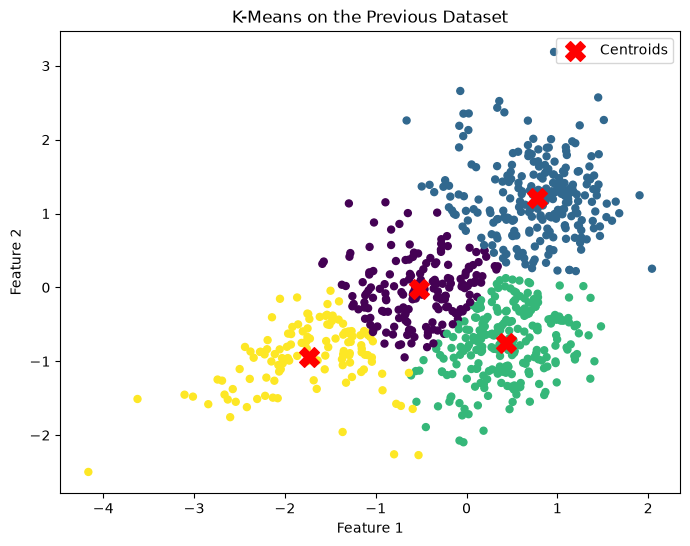

In [15]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Use the previously generated dataset
# X_scaled and y_true must already exist

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Apply K-Means
y_pred = kmeans.fit_predict(X_scaled)

# Evaluate
print("Total data points:", len(X_scaled))
print("Number of clusters:", len(set(y_pred)))
print("Inertia:", round(kmeans.inertia_, 4))
print("Silhouette Score:", round(silhouette_score(X_scaled, y_pred), 4))
print("Adjusted Rand Index:", round(adjusted_rand_score(y_true, y_pred), 4))

# Visualize the clustering results
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_pred,
    cmap="viridis",
    s=25
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color="red",
    marker="X",
    s=200,
    label="Centroids"
)

plt.title("K-Means on the Previous Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()

Total data points: 800
Number of clusters: 4
Silhouette Score: 0.3766
Adjusted Rand Index: 0.3924


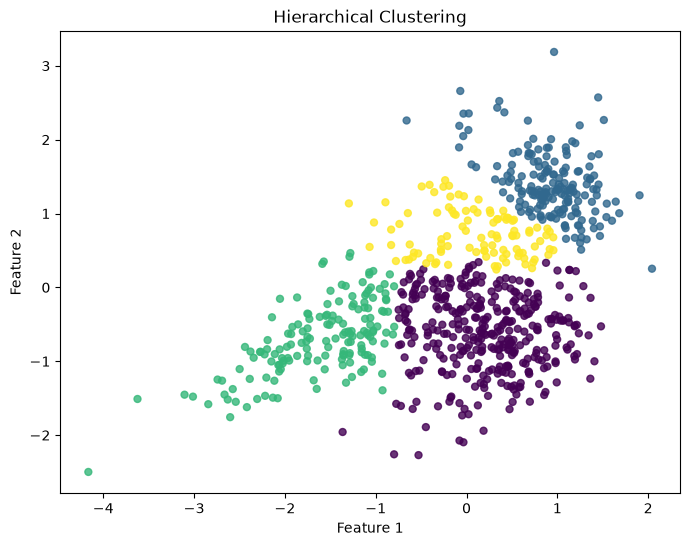

In [16]:

import matplotlib.pyplot as plt

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

# 1. Apply Hierarchical Clustering to the existing dataset
hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage="ward"
)

y_pred = hierarchical.fit_predict(X_scaled)

# 2. Evaluate clustering
print("Total data points:", len(X_scaled))
print("Number of clusters:", len(set(y_pred)))

print("Silhouette Score:",
      round(silhouette_score(X_scaled, y_pred), 4))

print("Adjusted Rand Index:",
      round(adjusted_rand_score(y_true, y_pred), 4))

# 3. Visualize the clusters
plt.figure(figsize=(8, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_pred,
    cmap="viridis",
    s=25,
    alpha=0.8
)

plt.title("Hierarchical Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


Fuzzy C-Means Results
---------------------
Total data points: 800
Number of clusters: 4
Iterations: 50
FPC: 0.6326
Silhouette Score: 0.4266
ARI Score: 0.3986


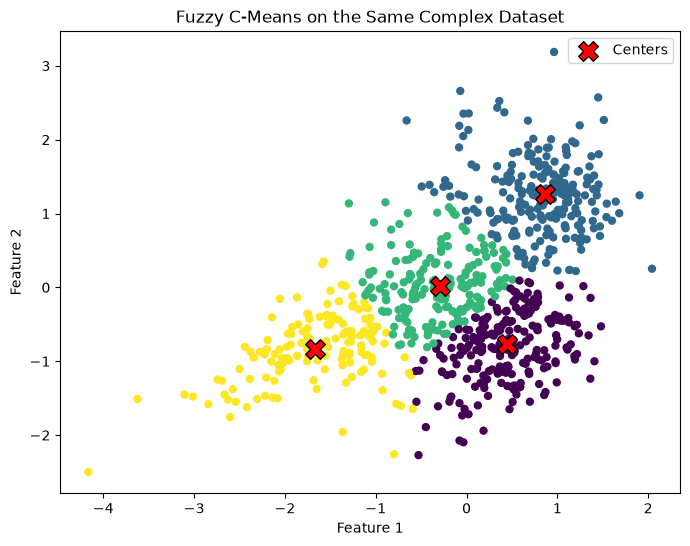

In [17]:

import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Reuse the existing dataset
data = X_scaled.T

# Apply Fuzzy C-Means
centers, membership, _, _, _, iterations, fpc = fuzz.cluster.cmeans(
    data=data,
    c=4,
    m=2,
    error=0.005,
    maxiter=1000,
    seed=42
)

# Assign each point to its highest-membership cluster
y_pred = np.argmax(membership, axis=0)

# Print evaluation scores
print("Fuzzy C-Means Results")
print("---------------------")
print("Total data points:", len(X_scaled))
print("Number of clusters:", len(centers))
print("Iterations:", iterations)
print("FPC:", round(fpc, 4))
print("Silhouette Score:", round(silhouette_score(X_scaled, y_pred), 4))
print("ARI Score:", round(adjusted_rand_score(y_true, y_pred), 4))

# Plot clusters and centers
plt.figure(figsize=(8, 6))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_pred, cmap="viridis", s=25)
plt.scatter(
    centers[:, 0], centers[:, 1],
    marker="X", color="red", edgecolor="black",
    s=200, label="Centers"
)
plt.title("Fuzzy C-Means on the Same Complex Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.legend()
plt.show()
